In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

os.listdir('/content/drive/MyDrive')

['Revenue-Figures 2.gsheet',
 'Revenue-Figures 2.xlsx',
 'Excel_RS',
 'cnw-1.docx',
 'Python lab',
 'DS lab',
 'DNV',
 'MathsLab',
 'one.ipynb - auto-6.pdf',
 'Iris (1).xlsx',
 'Colab Notebooks',
 'music.c',
 'CN Module II.gdoc',
 'CN Module III-Part 1.gdoc',
 'CN Module IV- Part 1.gdoc',
 'IPv4,IPv6,NAT- NETWORK  LAYER.gdoc',
 'CN Module I.gdoc',
 'S2MCA',
 'DM Concepts & Techniques _ Han&Kamber (3).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (2).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (1).gdoc',
 'DM Concepts & Techniques _ Han&Kamber.gdoc',
 'DOC-20260126-WA0021.pdf',
 'DOC-20260126-WA0021.gdoc',
 'Docker steps-1.pdf',
 'Docker steps-1.gdoc',
 'S3MCA',
 'ML_Lab',
 'PCOS_Project']

In [3]:
import os

project_path = '/content/drive/MyDrive/PCOS_Project'

os.listdir(project_path)

['PCOS_DATASET']

In [6]:
dataset_path = '/content/drive/MyDrive/PCOS_Project/PCOS_DATASET'

os.listdir(dataset_path)

['PCOS']

In [7]:
pcos_path = os.path.join(dataset_path, 'PCOS')

os.listdir(pcos_path)

['noninfected', 'infected']

#DATASET AUDIT
##Count Images

In [8]:
#Define Class Folder Paths
infected_path = os.path.join(pcos_path, 'infected')
noninfected_path = os.path.join(pcos_path, 'noninfected')

print("Infected folder:", infected_path)
print("Noninfected folder:", noninfected_path)

Infected folder: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected
Noninfected folder: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected


In [9]:
#Count All Files
print("Files in infected:", len(os.listdir(infected_path)))
print("Files in noninfected:", len(os.listdir(noninfected_path)))

Files in infected: 6784
Files in noninfected: 5000


In [10]:
#Count Actual Image Files
def count_images(folder):
    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    return sum(
        1 for file in os.listdir(folder)
        if file.lower().endswith(valid_extensions)
    )

infected_count = count_images(infected_path)
noninfected_count = count_images(noninfected_path)

print("Infected images:", infected_count)
print("Noninfected images:", noninfected_count)
print("Total images:", infected_count + noninfected_count)

Infected images: 6784
Noninfected images: 5000
Total images: 11784


In [11]:
# Calculate class percentages

total_images = infected_count + noninfected_count

infected_percentage = (infected_count / total_images) * 100
noninfected_percentage = (noninfected_count / total_images) * 100

print(f"Infected: {infected_count} ({infected_percentage:.2f}%)")
print(f"Noninfected: {noninfected_count} ({noninfected_percentage:.2f}%)")

Infected: 6784 (57.57%)
Noninfected: 5000 (42.43%)


##Image Dimensions & Color Modes

In [12]:
#Inspect Image Dimensions
from PIL import Image
from collections import Counter

def get_image_info(folder):
    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    sizes = []
    modes = Counter()

    for file in os.listdir(folder):

        if file.lower().endswith(valid_extensions):

            path = os.path.join(folder, file)

            try:
                with Image.open(path) as img:
                    sizes.append(img.size)
                    modes[img.mode] += 1

            except Exception:
                pass

    return sizes, modes


# Inspect both classes

for name, folder in {
    "Infected": infected_path,
    "Noninfected": noninfected_path
}.items():

    sizes, modes = get_image_info(folder)

    print("\n" + name)
    print("-" * 40)
    print("Readable images:", len(sizes))
    print("Unique dimensions:", len(Counter(sizes)))
    print("Image modes:", modes)
    print("\nMost common dimensions:")

    for size, count in Counter(sizes).most_common(10):
        print(f"{size}: {count}")


Infected
----------------------------------------
Readable images: 6784
Unique dimensions: 1362
Image modes: Counter({'RGB': 6784})

Most common dimensions:
(300, 300): 1590
(225, 225): 528
(343, 343): 480
(320, 320): 444
(299, 266): 412
(280, 259): 400
(233, 216): 386
(150, 150): 104
(266, 299): 84
(259, 280): 67

Noninfected
----------------------------------------
Readable images: 5000
Unique dimensions: 8
Image modes: Counter({'RGB': 5000})

Most common dimensions:
(984, 848): 1433
(850, 578): 960
(630, 436): 859
(315, 160): 727
(848, 984): 396
(578, 850): 262
(160, 315): 183
(436, 630): 180


In [4]:
#Find Unreadable Images
def find_unreadable_images(folder):

    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    unreadable = []

    for file in os.listdir(folder):

        if file.lower().endswith(valid_extensions):

            path = os.path.join(folder, file)

            try:
                with Image.open(path) as img:
                    img.verify()

            except Exception as e:
                unreadable.append((file, str(e)))

    return unreadable


# Check both classes

for name, folder in {
    "Infected": infected_path,
    "Noninfected": noninfected_path
}.items():

    bad_files = find_unreadable_images(folder)

    print("\n" + name)
    print("-" * 40)
    print("Unreadable files:", len(bad_files))

    for file, error in bad_files[:20]:
        print(file, "→", error)

NameError: name 'infected_path' is not defined

INFECTED SAMPLES


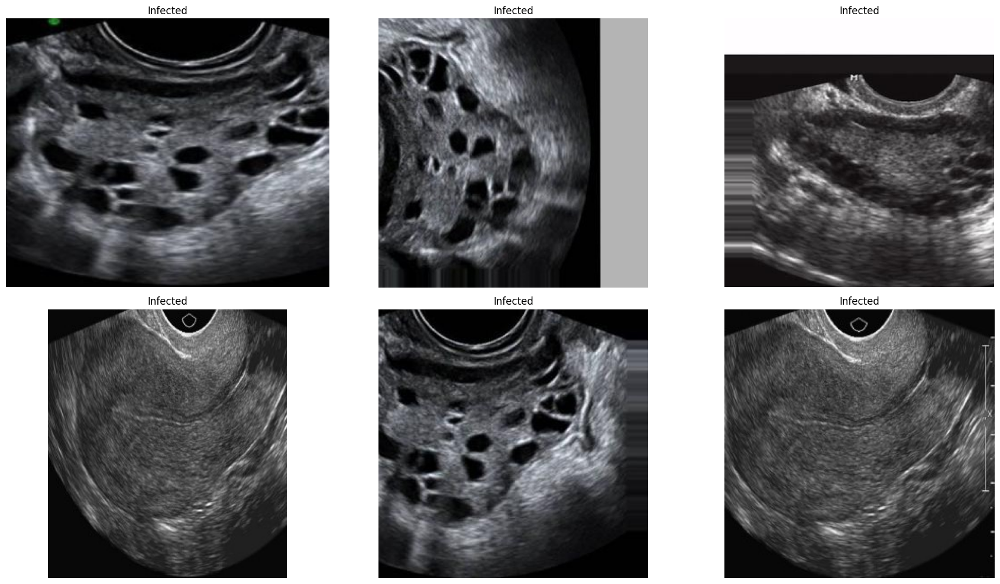

NONINFECTED SAMPLES


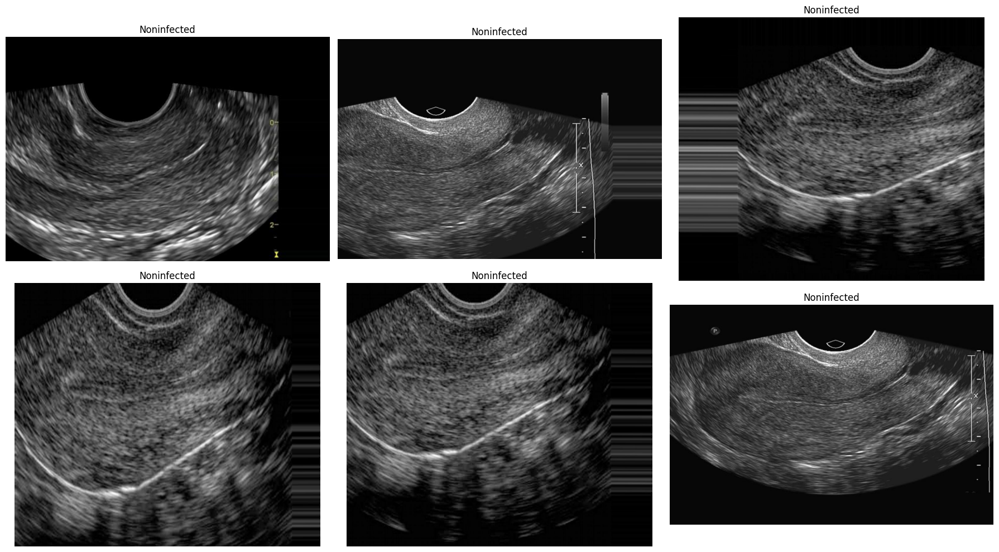

In [14]:
#Display Random Samples
import matplotlib.pyplot as plt
import random
from PIL import Image

def get_random_images(folder, n=6):

    valid_extensions = (
        '.jpg', '.jpeg', '.png',
        '.bmp', '.tif', '.tiff'
    )

    files = [
        file for file in os.listdir(folder)
        if file.lower().endswith(valid_extensions)
    ]

    return random.sample(files, min(n, len(files)))


def display_samples(folder, title, n=6):

    files = get_random_images(folder, n)

    plt.figure(figsize=(18, 10))

    for i, file in enumerate(files):

        path = os.path.join(folder, file)

        with Image.open(path) as img:
            image = img.copy()

        plt.subplot(2, 3, i + 1)
        plt.imshow(image)
        plt.title(title)
        plt.axis('off')

    plt.tight_layout()
    plt.show()


print("INFECTED SAMPLES")
display_samples(infected_path, "Infected", 6)

print("NONINFECTED SAMPLES")
display_samples(noninfected_path, "Noninfected", 6)

##Exact Duplicate Detection

In [15]:
#Calculate Exact Duplicate Groups
import hashlib
from collections import defaultdict

def get_image_hash(file_path):
    with open(file_path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()


# All dataset classes
all_folders = {
    "infected": infected_path,
    "noninfected": noninfected_path
}

hash_to_files = defaultdict(list)

valid_extensions = (
    '.jpg', '.jpeg', '.png',
    '.bmp', '.tif', '.tiff'
)

for class_name, folder_path in all_folders.items():

    for file in os.listdir(folder_path):

        if file.lower().endswith(valid_extensions):

            file_path = os.path.join(folder_path, file)

            try:
                # Verify that the file is a valid image
                with Image.open(file_path) as img:
                    img.verify()

                # Calculate file fingerprint
                image_hash = get_image_hash(file_path)

                hash_to_files[image_hash].append(
                    (class_name, file)
                )

            except Exception:
                pass


# Find duplicate groups
duplicates = {
    image_hash: files
    for image_hash, files in hash_to_files.items()
    if len(files) > 1
}


print("Total readable files:", sum(len(v) for v in hash_to_files.values()))
print("Unique image contents:", len(hash_to_files))
print("Duplicate groups:", len(duplicates))

Total readable files: 11784
Unique image contents: 3996
Duplicate groups: 1956


In [16]:
#See the duplicate-group sizes
from collections import Counter

group_sizes = Counter(
    len(files)
    for files in hash_to_files.values()
)

print("Duplicate group size distribution:")

for size, count in sorted(group_sizes.items()):
    print(f"{count} groups contain {size} identical files")

Duplicate group size distribution:
2040 groups contain 1 identical files
482 groups contain 2 identical files
12 groups contain 3 identical files
366 groups contain 4 identical files
1 groups contain 5 identical files
741 groups contain 6 identical files
3 groups contain 7 identical files
351 groups contain 8 identical files


In [17]:
#Check for duplicates across classes
cross_class_duplicates = []

for image_hash, files in hash_to_files.items():

    classes = set(
        class_name
        for class_name, filename in files
    )

    if len(classes) > 1:
        cross_class_duplicates.append(files)


print(
    "Duplicate groups appearing in BOTH classes:",
    len(cross_class_duplicates)
)


# Show first 10 examples if any exist

for i, files in enumerate(cross_class_duplicates[:10]):

    print(f"\nCross-class duplicate group {i + 1}")

    for class_name, filename in files:
        print(" ", class_name, "→", filename)

Duplicate groups appearing in BOTH classes: 0


##Unique Class Distribution

In [18]:
from collections import Counter

unique_class_counts = Counter()

for image_hash, files in hash_to_files.items():

    # Take the class of the first file.
    # We already verified that there are no
    # cross-class duplicate groups.

    class_name, filename = files[0]

    unique_class_counts[class_name] += 1


print("Unique image class distribution")
print("-" * 40)

print(
    "Infected:",
    unique_class_counts["infected"]
)

print(
    "Noninfected:",
    unique_class_counts["noninfected"]
)

total_unique = sum(unique_class_counts.values())

print(
    "Total unique:",
    total_unique
)

print("\nPercentages:")

print(
    f"Infected: "
    f"{unique_class_counts['infected'] / total_unique * 100:.2f}%"
)

print(
    f"Noninfected: "
    f"{unique_class_counts['noninfected'] / total_unique * 100:.2f}%"
)

Unique image class distribution
----------------------------------------
Infected: 3184
Noninfected: 812
Total unique: 3996

Percentages:
Infected: 79.68%
Noninfected: 20.32%


##Analyze Duplicate Rate by Class

In [19]:
# Calculate raw and unique image counts for each class

raw_counts = {
    "infected": len([
        f for f in os.listdir(infected_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))
    ]),
    "noninfected": len([
        f for f in os.listdir(noninfected_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'))
    ])
}

unique_counts = {
    "infected": unique_class_counts["infected"],
    "noninfected": unique_class_counts["noninfected"]
}

print("Class-wise duplication analysis")
print("-" * 50)

for class_name in ["infected", "noninfected"]:

    raw = raw_counts[class_name]
    unique = unique_counts[class_name]

    duplicate_copies = raw - unique
    duplicate_percentage = (duplicate_copies / raw) * 100

    print(f"\n{class_name.capitalize()}")
    print(f"Raw images: {raw}")
    print(f"Unique images: {unique}")
    print(f"Duplicate copies: {duplicate_copies}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Class-wise duplication analysis
--------------------------------------------------

Infected
Raw images: 6784
Unique images: 3184
Duplicate copies: 3600
Duplicate percentage: 53.07%

Noninfected
Raw images: 5000
Unique images: 812
Duplicate copies: 4188
Duplicate percentage: 83.76%


#Near-Duplicate Investigation

In [21]:
#Install the perceptual hashing library
!pip install ImageHash -q

In [22]:
#Import the required libraries
import imagehash
from PIL import Image
import os
from collections import defaultdict

In [23]:
#Create a list of our 3,996 unique images
# Create a list containing one representative
# from each unique image-content group

unique_images = []

for image_hash, files in hash_to_files.items():

    class_name, filename = files[0]

    if class_name == "infected":
        folder = infected_path
    else:
        folder = noninfected_path

    file_path = os.path.join(folder, filename)

    unique_images.append({
        "path": file_path,
        "class": class_name,
        "filename": filename
    })

print("Number of images for near-duplicate analysis:",
      len(unique_images))

Number of images for near-duplicate analysis: 3996


In [24]:
#Generate perceptual hashes
phash_data = []

for i, item in enumerate(unique_images):

    try:
        with Image.open(item["path"]) as img:
            img = img.convert("RGB")

            hash_value = imagehash.phash(img)

        phash_data.append({
            "path": item["path"],
            "class": item["class"],
            "filename": item["filename"],
            "hash": hash_value
        })

    except Exception as e:
        print("Error:", item["filename"], e)

print("Successfully generated pHash for:",
      len(phash_data),
      "images")

Successfully generated pHash for: 3996 images


In [25]:
#Find highly similar images
near_duplicate_pairs = []

threshold = 4

for i in range(len(phash_data)):

    hash1 = phash_data[i]["hash"]

    for j in range(i + 1, len(phash_data)):

        hash2 = phash_data[j]["hash"]

        distance = hash1 - hash2

        if distance <= threshold:

            near_duplicate_pairs.append({
                "image1": phash_data[i],
                "image2": phash_data[j],
                "distance": distance
            })

print("Number of highly similar pairs:", len(near_duplicate_pairs))

Number of highly similar pairs: 8365


In [26]:
#See the suspicious pairs
for i, pair in enumerate(near_duplicate_pairs[:20]):

    img1 = pair["image1"]
    img2 = pair["image2"]

    print(f"\nPair {i + 1}")
    print("Distance:", pair["distance"])

    print("Image 1:")
    print(" Class:", img1["class"])
    print(" File :", img1["filename"])

    print("Image 2:")
    print(" Class:", img2["class"])
    print(" File :", img2["filename"])


Pair 1
Distance: 4
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image12545.jpg

Pair 2
Distance: 2
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image12575.jpg

Pair 3
Distance: 2
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image12613.jpg

Pair 4
Distance: 4
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image12794.jpg

Pair 5
Distance: 2
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image13055.jpg

Pair 6
Distance: 4
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image13065.jpg

Pair 7
Distance: 0
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image13151.jpg

Pair 8
Distance: 4
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image10704.jpg

Pair 9
Distance: 4
Image 1:
 Class: infected
 File : im

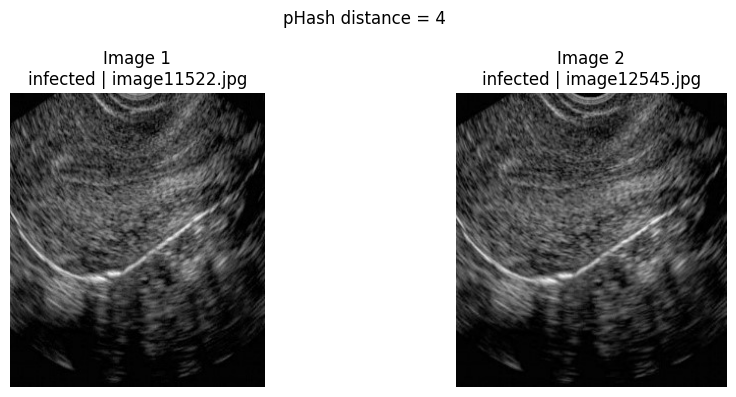

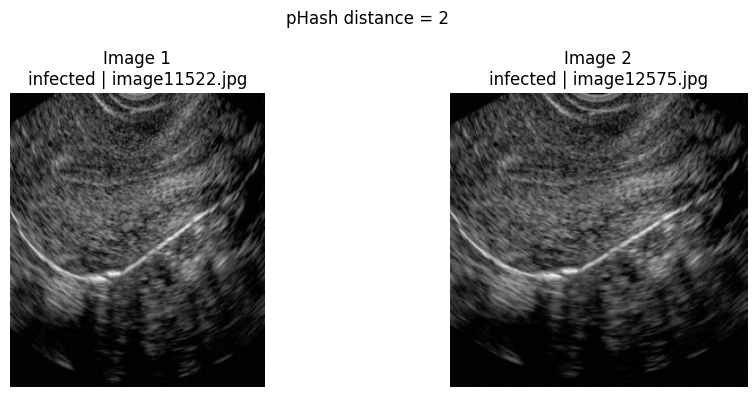

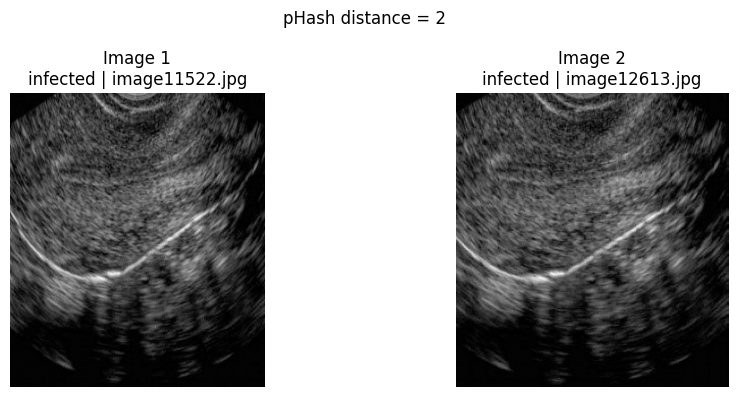

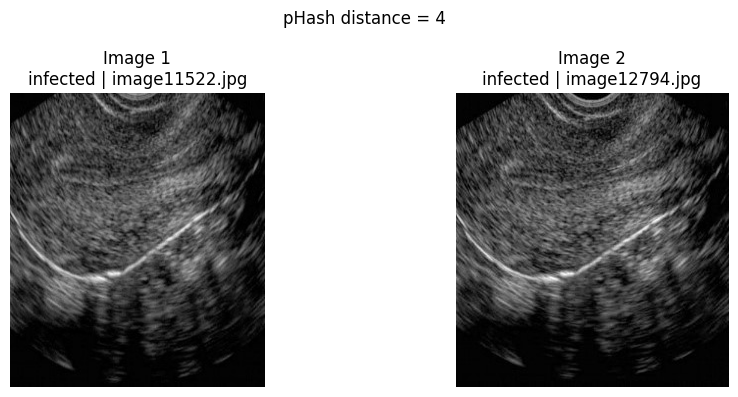

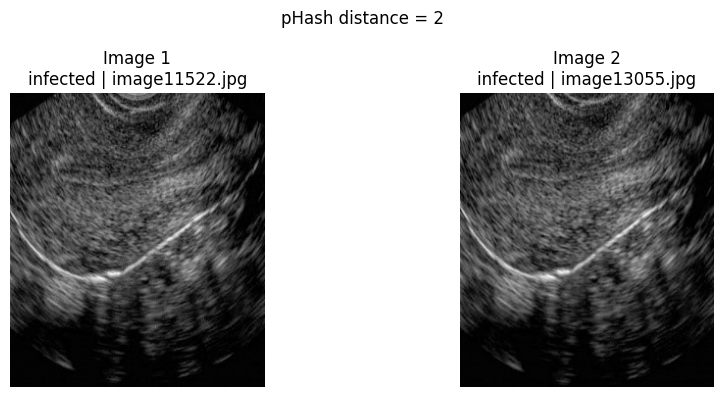

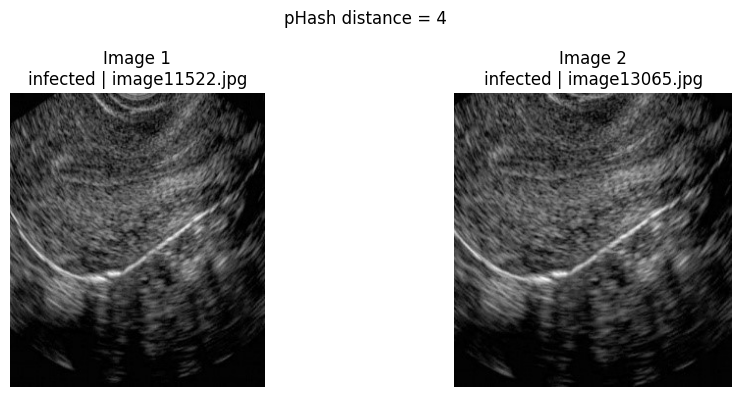

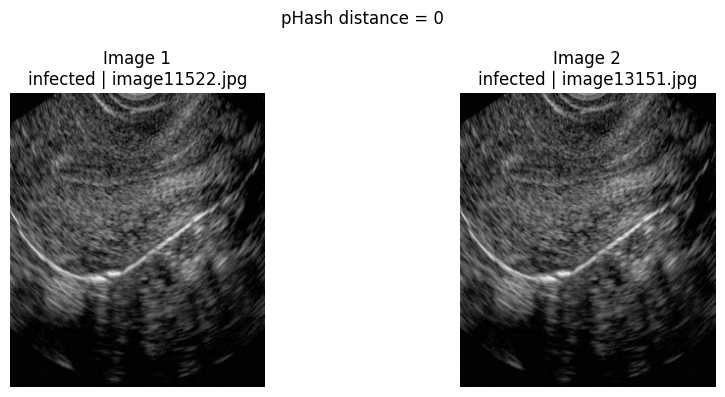

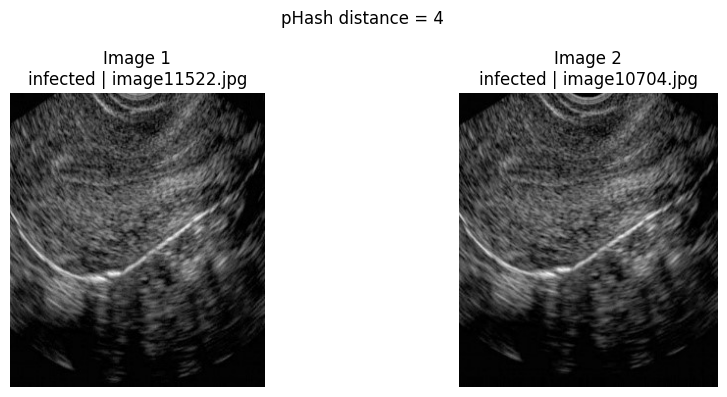

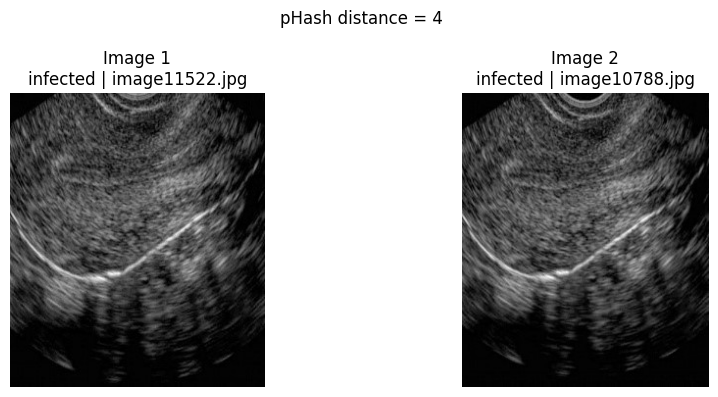

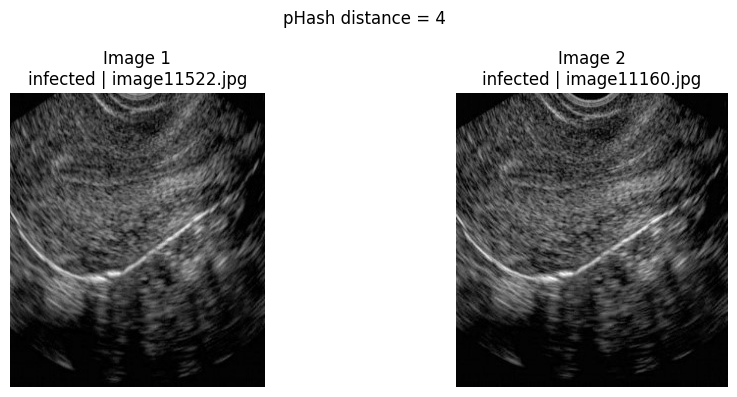

In [27]:
#Visualize suspicious pairs
import matplotlib.pyplot as plt

def show_near_duplicate_pairs(pairs, n=10):

    n = min(n, len(pairs))

    for i in range(n):

        pair = pairs[i]

        img1 = pair["image1"]
        img2 = pair["image2"]

        with Image.open(img1["path"]) as im1:
            im1 = im1.convert("RGB").copy()

        with Image.open(img2["path"]) as im2:
            im2 = im2.convert("RGB").copy()

        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(im1)
        plt.title(
            f"Image 1\n"
            f"{img1['class']} | {img1['filename']}"
        )
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(im2)
        plt.title(
            f"Image 2\n"
            f"{img2['class']} | {img2['filename']}"
        )
        plt.axis("off")

        plt.suptitle(
            f"pHash distance = {pair['distance']}"
        )

        plt.tight_layout()
        plt.show()


show_near_duplicate_pairs(near_duplicate_pairs, n=10)

#Separate the strongest candidates

In [28]:
# Find pairs with exactly identical perceptual hashes

zero_distance_pairs = [
    pair
    for pair in near_duplicate_pairs
    if pair["distance"] == 0
]

print("Pairs with pHash distance = 0:",
      len(zero_distance_pairs))

Pairs with pHash distance = 0: 1119


In [29]:
for i, pair in enumerate(zero_distance_pairs[:30]):

    img1 = pair["image1"]
    img2 = pair["image2"]

    print(f"\nPair {i + 1}")

    print("Image 1:")
    print(" Class:", img1["class"])
    print(" File :", img1["filename"])

    print("Image 2:")
    print(" Class:", img2["class"])
    print(" File :", img2["filename"])

    print("pHash distance:", pair["distance"])


Pair 1
Image 1:
 Class: infected
 File : image11522.jpg
Image 2:
 Class: infected
 File : image13151.jpg
pHash distance: 0

Pair 2
Image 1:
 Class: infected
 File : image11533.jpg
Image 2:
 Class: infected
 File : image11529.jpg
pHash distance: 0

Pair 3
Image 1:
 Class: infected
 File : image11520.jpg
Image 2:
 Class: infected
 File : image13149.jpg
pHash distance: 0

Pair 4
Image 1:
 Class: infected
 File : image11530.jpg
Image 2:
 Class: infected
 File : image11534.jpg
pHash distance: 0

Pair 5
Image 1:
 Class: infected
 File : image11530.jpg
Image 2:
 Class: infected
 File : image11962.jpg
pHash distance: 0

Pair 6
Image 1:
 Class: infected
 File : image11530.jpg
Image 2:
 Class: infected
 File : image11528.jpg
pHash distance: 0

Pair 7
Image 1:
 Class: infected
 File : image11534.jpg
Image 2:
 Class: infected
 File : image11962.jpg
pHash distance: 0

Pair 8
Image 1:
 Class: infected
 File : image11534.jpg
Image 2:
 Class: infected
 File : image11528.jpg
pHash distance: 0

Pair 9


#Visualize the distance-0 pairs

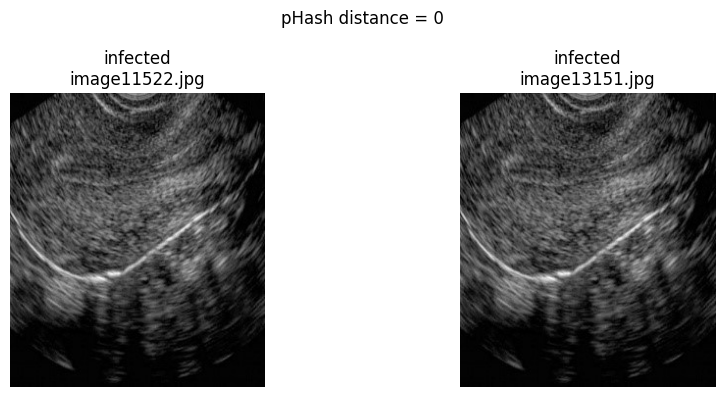

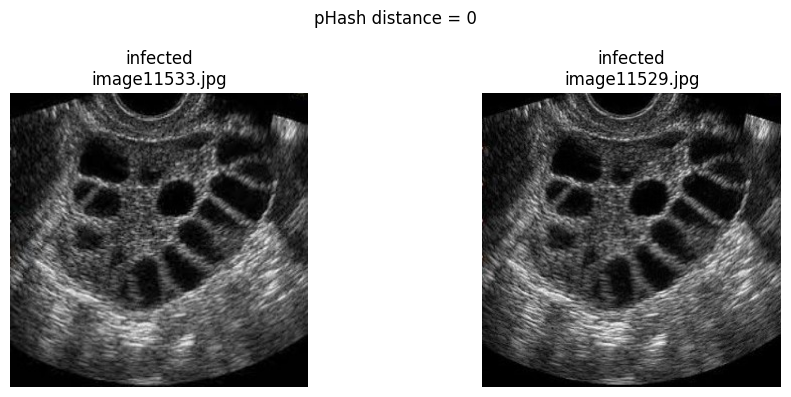

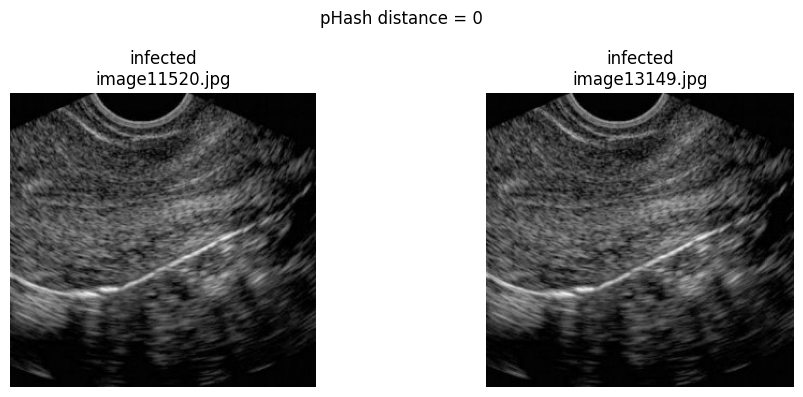

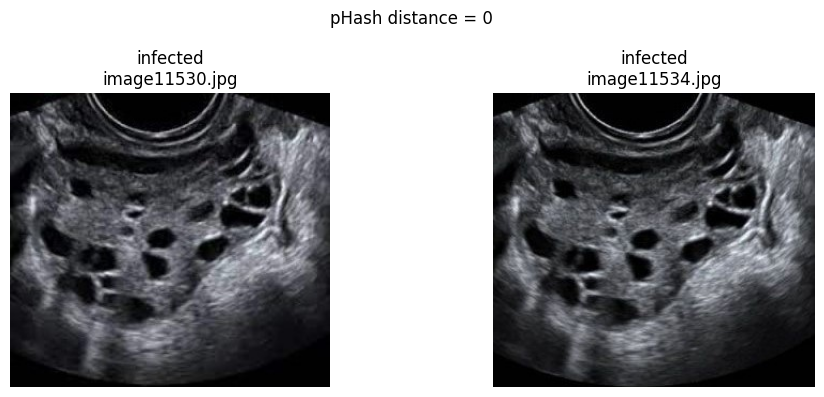

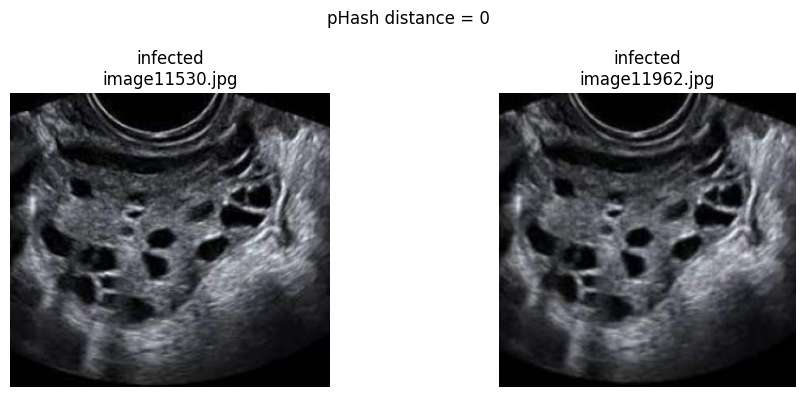

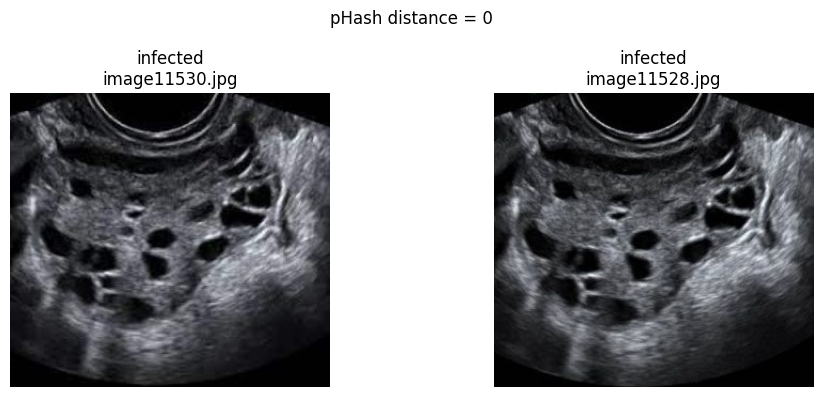

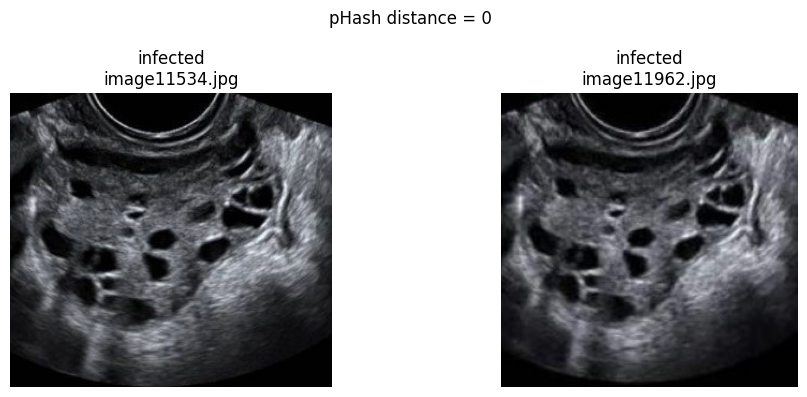

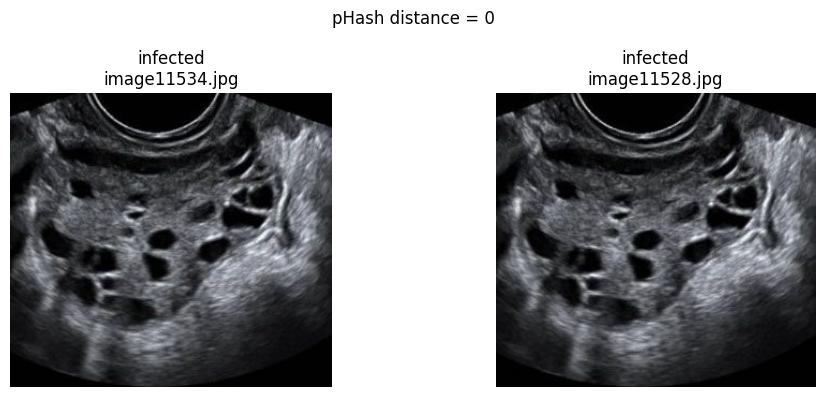

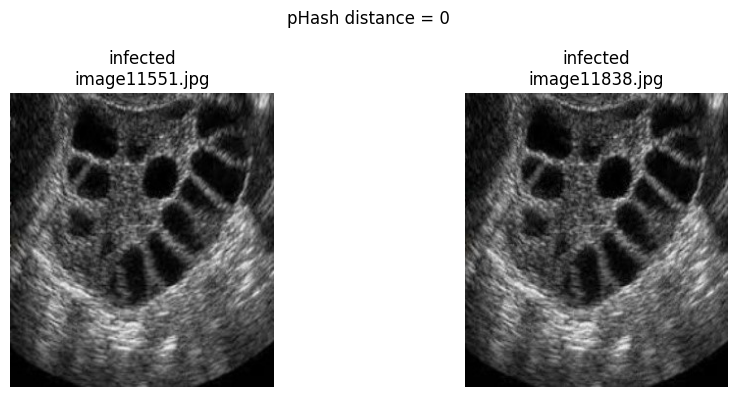

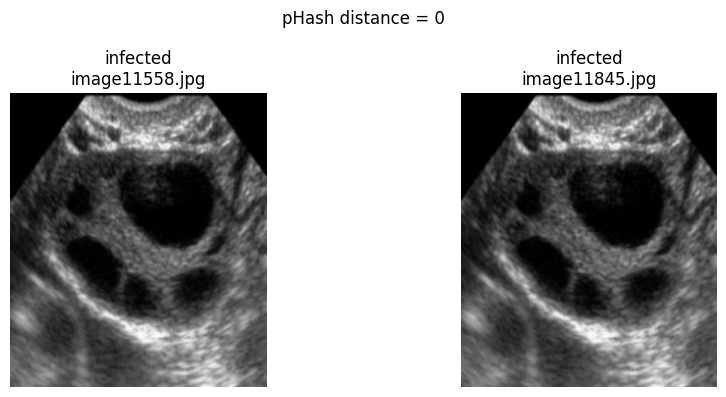

In [30]:
import matplotlib.pyplot as plt

def show_zero_distance_pairs(pairs, n=10):

    n = min(n, len(pairs))

    for i in range(n):

        pair = pairs[i]

        img1 = pair["image1"]
        img2 = pair["image2"]

        with Image.open(img1["path"]) as im1:
            im1 = im1.convert("RGB").copy()

        with Image.open(img2["path"]) as im2:
            im2 = im2.convert("RGB").copy()

        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(im1)
        plt.title(
            f"{img1['class']}\n{img1['filename']}"
        )
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(im2)
        plt.title(
            f"{img2['class']}\n{img2['filename']}"
        )
        plt.axis("off")

        plt.suptitle(
            f"pHash distance = {pair['distance']}"
        )

        plt.tight_layout()
        plt.show()


show_zero_distance_pairs(zero_distance_pairs, n=10)

##Group the pHash-0 images

In [31]:
from collections import defaultdict, deque

# Build a graph from pHash distance-0 pairs

graph = defaultdict(set)

for pair in zero_distance_pairs:

    file1 = pair["image1"]["path"]
    file2 = pair["image2"]["path"]

    graph[file1].add(file2)
    graph[file2].add(file1)


# Find connected groups

visited = set()
zero_hash_groups = []

for image in graph:

    if image in visited:
        continue

    group = []
    queue = deque([image])
    visited.add(image)

    while queue:

        current = queue.popleft()
        group.append(current)

        for neighbour in graph[current]:

            if neighbour not in visited:
                visited.add(neighbour)
                queue.append(neighbour)

    zero_hash_groups.append(group)


print("pHash distance-0 groups:", len(zero_hash_groups))
print(
    "Images involved in distance-0 groups:",
    sum(len(group) for group in zero_hash_groups)
)

print(
    "Largest distance-0 group:",
    max(len(group) for group in zero_hash_groups)
)

pHash distance-0 groups: 342
Images involved in distance-0 groups: 818
Largest distance-0 group: 27


In [33]:
#Understand the group-size distribution
group_size_distribution = Counter(
    len(group)
    for group in zero_hash_groups
)

print("pHash distance-0 group size distribution")
print("-" * 50)

for size, count in sorted(group_size_distribution.items()):
    print(
        f"{count} groups contain {size} visually identical images"
    )

pHash distance-0 group size distribution
--------------------------------------------------
290 groups contain 2 visually identical images
30 groups contain 3 visually identical images
8 groups contain 4 visually identical images
7 groups contain 5 visually identical images
2 groups contain 6 visually identical images
2 groups contain 7 visually identical images
1 groups contain 10 visually identical images
1 groups contain 18 visually identical images
1 groups contain 27 visually identical images


In [34]:
#Display complete groups
for i, group in enumerate(zero_hash_groups[:20]):

    print(f"\nDistance-0 Group {i + 1}")
    print("Number of images:", len(group))

    for path in group:
        print(" ", path)


Distance-0 Group 1
Number of images: 2
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11522.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image13151.jpg

Distance-0 Group 2
Number of images: 2
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11533.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11529.jpg

Distance-0 Group 3
Number of images: 2
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11520.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image13149.jpg

Distance-0 Group 4
Number of images: 4
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11530.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11962.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11528.jpg
  /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image11534.jpg

Distance-0 Group 5
Number of images: 2


##SSIM

In [35]:
#Install SSIM library
!pip install scikit-image -q

In [36]:
#Import SSIM
from skimage.metrics import structural_similarity as ssim
import numpy as np

In [42]:
#Create an SSIM comparison function
def calculate_ssim(path1, path2, size=(256, 256)):

    with Image.open(path1) as img1:
        img1 = img1.convert("L")
        img1 = img1.resize(size)

    with Image.open(path2) as img2:
        img2 = img2.convert("L")
        img2 = img2.resize(size)

    img1_array = np.array(img1)
    img2_array = np.array(img2)

    score = ssim(
        img1_array,
        img2_array,
        data_range=255
    )

    return score

In [38]:
#Verify all pHash-0 groups
ssim_results = []

for group_id, group in enumerate(zero_hash_groups):

    reference = group[0]

    for other in group[1:]:

        try:
            score = calculate_ssim(reference, other)

            ssim_results.append({
                "group": group_id + 1,
                "reference": reference,
                "comparison": other,
                "ssim": score
            })

        except Exception as e:
            print("Error:", e)


print("SSIM comparisons completed:", len(ssim_results))

SSIM comparisons completed: 476


In [39]:
#SSIM Distribution
scores = [result["ssim"] for result in ssim_results]

print("Minimum SSIM:", min(scores))
print("Maximum SSIM:", max(scores))
print("Average SSIM:", sum(scores) / len(scores))

Minimum SSIM: 0.17736729402431198
Maximum SSIM: 0.9961481826568613
Average SSIM: 0.722744413845184


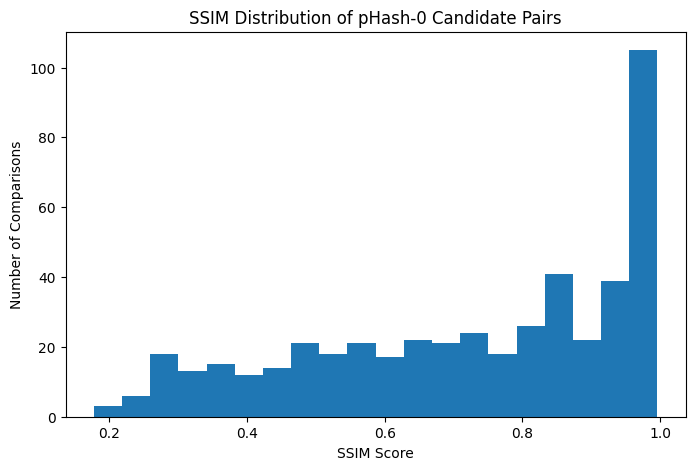

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(scores, bins=20)

plt.xlabel("SSIM Score")
plt.ylabel("Number of Comparisons")
plt.title("SSIM Distribution of pHash-0 Candidate Pairs")

plt.show()

In [41]:
# Sort from least similar to most similar

sorted_results = sorted(
    ssim_results,
    key=lambda x: x["ssim"]
)

print("10 lowest-SSIM pHash-0 pairs")
print("-" * 60)

for result in sorted_results[:10]:

    print("\nGroup:", result["group"])
    print("SSIM:", result["ssim"])
    print("Reference:", result["reference"])
    print("Comparison:", result["comparison"])

10 lowest-SSIM pHash-0 pairs
------------------------------------------------------------

Group: 52
SSIM: 0.17736729402431198
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12299.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image10669.jpg

Group: 122
SSIM: 0.17846910179401707
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12772.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12786.jpg

Group: 65
SSIM: 0.19340838831737664
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12537.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image10758.jpg

Group: 65
SSIM: 0.21839289464505923
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12537.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image13078.jpg

Group: 63
SSIM: 0.22152437785897997
Referenc

In [43]:
#Analyse SSIM Thresholds
thresholds = [0.90, 0.92, 0.95, 0.97, 0.98, 0.99]

print("SSIM threshold analysis")
print("-" * 50)

for threshold in thresholds:

    count = sum(
        result["ssim"] >= threshold
        for result in ssim_results
    )

    percentage = (count / len(ssim_results)) * 100

    print(
        f"SSIM >= {threshold}: "
        f"{count} pairs ({percentage:.2f}%)"
    )

SSIM threshold analysis
--------------------------------------------------
SSIM >= 0.9: 155 pairs (32.56%)
SSIM >= 0.92: 141 pairs (29.62%)
SSIM >= 0.95: 114 pairs (23.95%)
SSIM >= 0.97: 59 pairs (12.39%)
SSIM >= 0.98: 36 pairs (7.56%)
SSIM >= 0.99: 28 pairs (5.88%)


In [44]:
#Show the strongest candidates
highest_ssim = sorted(
    ssim_results,
    key=lambda x: x["ssim"],
    reverse=True
)

print("20 highest-SSIM pairs")
print("-" * 60)

for result in highest_ssim[:20]:

    print("\nGroup:", result["group"])
    print("SSIM:", result["ssim"])
    print("Reference:", result["reference"])
    print("Comparison:", result["comparison"])

20 highest-SSIM pairs
------------------------------------------------------------

Group: 194
SSIM: 0.9961481826568613
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image10525.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected/Image_resize_671  (916).jpg

Group: 199
SSIM: 0.9959657092867014
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image10550.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected/Image_resize_671  (853).jpg

Group: 221
SSIM: 0.9957472042508978
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image10747.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected/Image_SetB129.jpg

Group: 48
SSIM: 0.9957068873743794
Reference: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/infected/image12278.jpg
Comparison: /content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS/noninfected/Image_resize_671  (1066).jpg

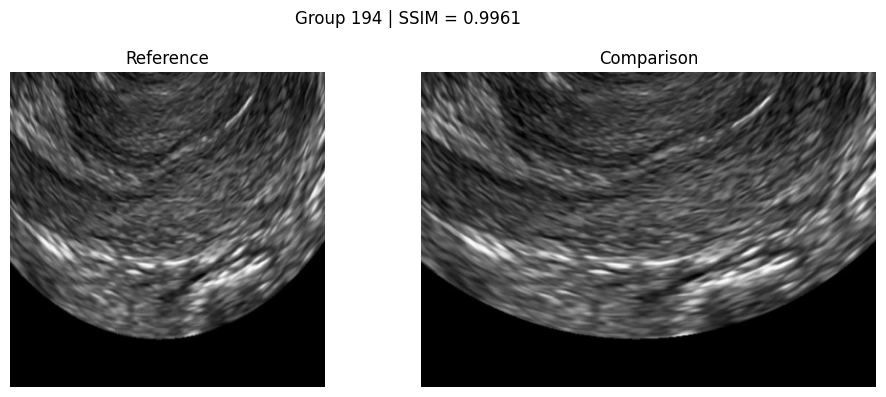

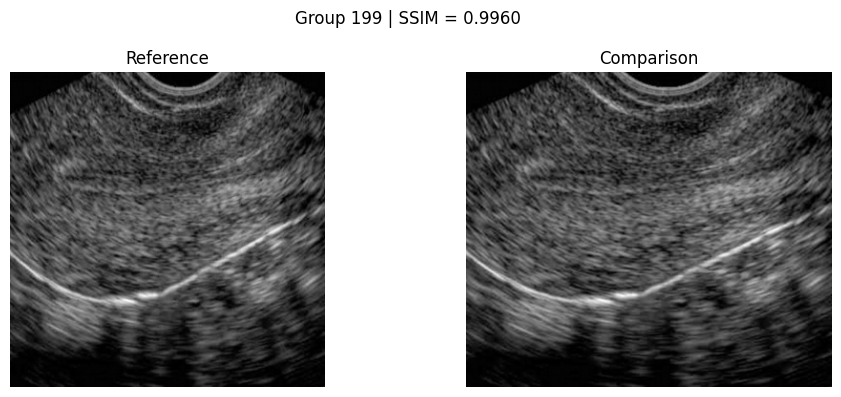

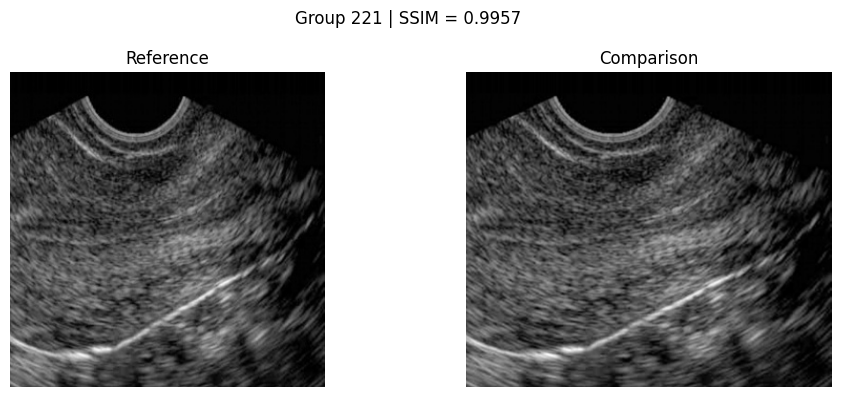

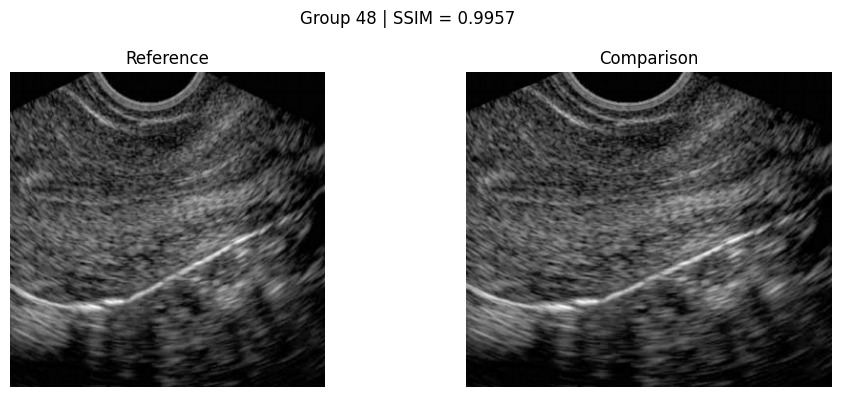

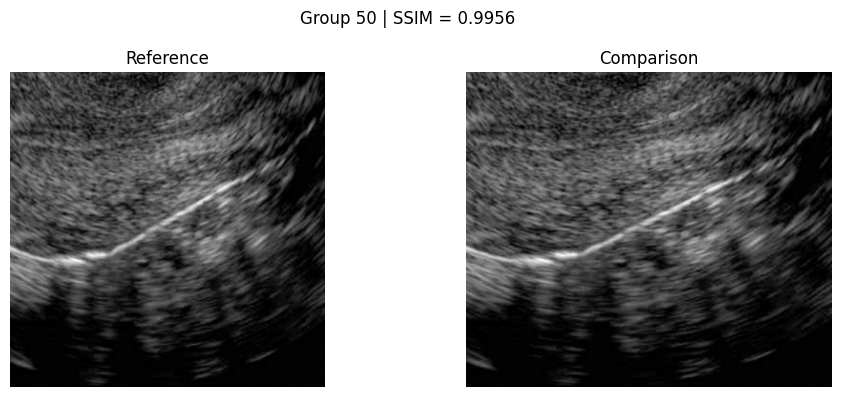

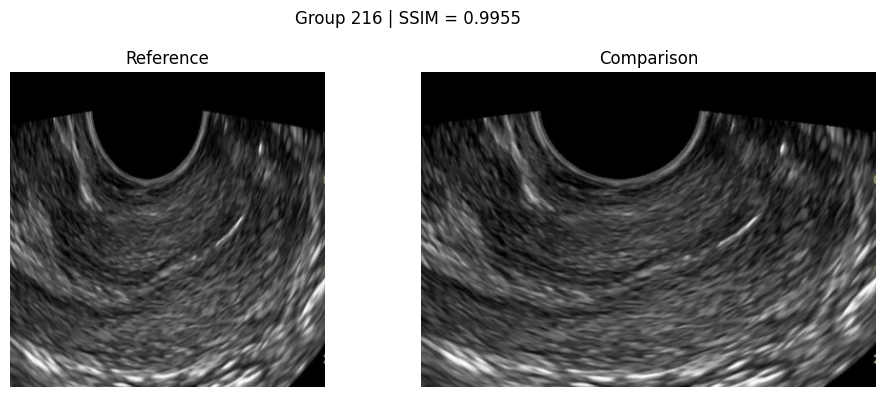

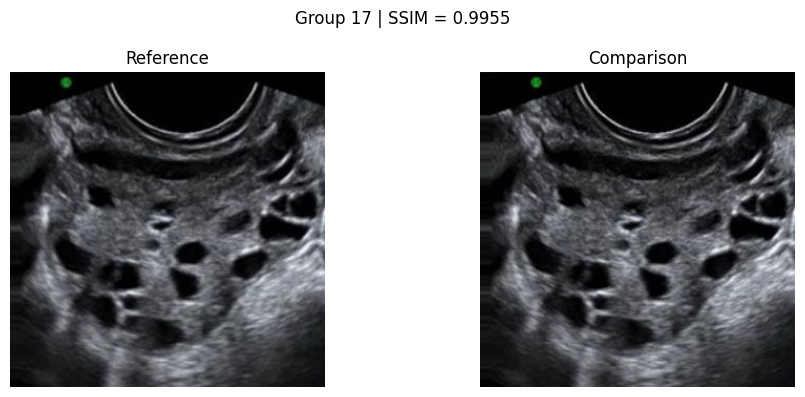

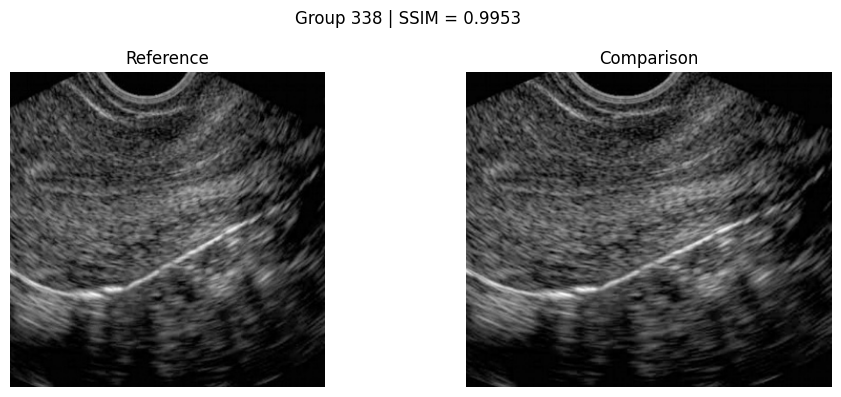

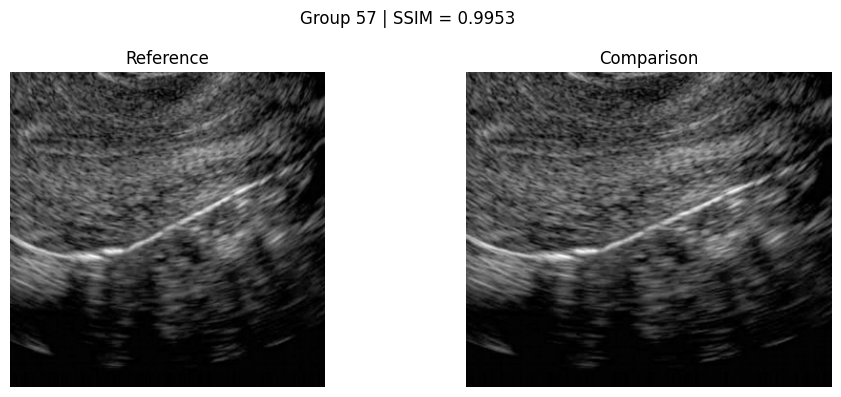

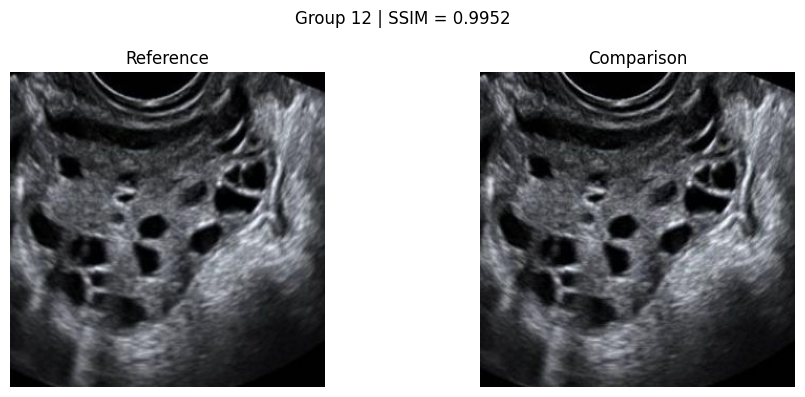

In [45]:
#Visualize the strongest candidates
strong_candidates = highest_ssim[:10]

for i, result in enumerate(strong_candidates):

    with Image.open(result["reference"]) as img1:
        img1 = img1.convert("RGB").copy()

    with Image.open(result["comparison"]) as img2:
        img2 = img2.convert("RGB").copy()

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img1)
    plt.title("Reference")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(img2)
    plt.title("Comparison")
    plt.axis("off")

    plt.suptitle(
        f"Group {result['group']} | SSIM = {result['ssim']:.4f}"
    )

    plt.tight_layout()
    plt.show()

##Cross-class near-duplicate analysis

In [48]:
# Create a quick path → class lookup

path_to_class = {
    item["path"]: item["class"]
    for item in phash_data
}

cross_class_zero_groups = []

for group_id, group in enumerate(zero_hash_groups):

    classes = {
        path_to_class[path]
        for path in group
    }

    if len(classes) > 1:

        cross_class_zero_groups.append({
            "group_id": group_id + 1,
            "group": group,
            "classes": classes
        })


print(
    "pHash distance-0 groups appearing in BOTH classes:",
    len(cross_class_zero_groups)
)

pHash distance-0 groups appearing in BOTH classes: 30


In [49]:
#Show those cross-class groups
for item in cross_class_zero_groups:

    print("\nGroup:", item["group_id"])
    print("Classes:", item["classes"])
    print("Number of images:", len(item["group"]))

    for path in item["group"]:

        print(
            " ",
            path_to_class[path],
            "→",
            os.path.basename(path)
        )


Group: 48
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image12278.jpg
  noninfected → Image_resize_671  (1066).jpg

Group: 50
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image12288.jpg
  noninfected → Image_SetB054.jpg

Group: 57
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image12386.jpg
  noninfected → Image_SetB079.jpg

Group: 80
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image12549.jpg
  noninfected → Image_SetB123.jpg

Group: 157
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image12934.jpg
  noninfected → Image_SetB176.jpg

Group: 192
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image10514.jpg
  noninfected → Image_resize_671  (934).jpg

Group: 193
Classes: {'infected', 'noninfected'}
Number of images: 2
  infected → image10539.jpg
  noninfected → Image_resize_671  (880).jpg

Group: 194
Classes: {'infected', 'noninfected'}
Number 

In [50]:
#How many cross-class images?
cross_class_image_count = sum(
    len(item["group"])
    for item in cross_class_zero_groups
)

print(
    "Images involved in cross-class pHash-0 groups:",
    cross_class_image_count
)

Images involved in cross-class pHash-0 groups: 60


In [51]:
#Check the SSIM of cross-class groups
cross_class_ssim = []

for result in ssim_results:

    class1 = path_to_class[result["reference"]]
    class2 = path_to_class[result["comparison"]]

    if class1 != class2:

        cross_class_ssim.append({
            **result,
            "class1": class1,
            "class2": class2
        })


print(
    "Cross-class pHash-0 comparisons:",
    len(cross_class_ssim)
)

Cross-class pHash-0 comparisons: 30


In [52]:
if cross_class_ssim:

    scores = [
        item["ssim"]
        for item in cross_class_ssim
    ]

    print("Minimum SSIM:", min(scores))
    print("Maximum SSIM:", max(scores))
    print("Average SSIM:", sum(scores) / len(scores))

Minimum SSIM: 0.9878200271455354
Maximum SSIM: 0.9961481826568613
Average SSIM: 0.9932457014648796


In [53]:
#strongest cross-class conflicts
cross_class_ssim_sorted = sorted(
    cross_class_ssim,
    key=lambda x: x["ssim"],
    reverse=True
)

print("Top 20 cross-class visually similar pairs")
print("-" * 70)

for result in cross_class_ssim_sorted[:20]:

    print("\nGroup:", result["group"])
    print("SSIM:", result["ssim"])

    print(
        result["class1"],
        "→",
        os.path.basename(result["reference"])
    )

    print(
        result["class2"],
        "→",
        os.path.basename(result["comparison"])
    )

Top 20 cross-class visually similar pairs
----------------------------------------------------------------------

Group: 194
SSIM: 0.9961481826568613
infected → image10525.jpg
noninfected → Image_resize_671  (916).jpg

Group: 199
SSIM: 0.9959657092867014
infected → image10550.jpg
noninfected → Image_resize_671  (853).jpg

Group: 221
SSIM: 0.9957472042508978
infected → image10747.jpg
noninfected → Image_SetB129.jpg

Group: 48
SSIM: 0.9957068873743794
infected → image12278.jpg
noninfected → Image_resize_671  (1066).jpg

Group: 50
SSIM: 0.9956207071420068
infected → image12288.jpg
noninfected → Image_SetB054.jpg

Group: 216
SSIM: 0.9955281430944724
infected → image10684.jpg
noninfected → Image_resize_671  (552).jpg

Group: 338
SSIM: 0.9952828739256678
infected → image10447.jpg
noninfected → Image_SetB345.jpg

Group: 57
SSIM: 0.9952666264675913
infected → image12386.jpg
noninfected → Image_SetB079.jpg

Group: 339
SSIM: 0.99510728157277
infected → image10444.jpg
noninfected → Image_SetB339.

##Find ALL cross-class pHash candidates

In [54]:
# Find all near-duplicate candidates (distance <= 4)
# that occur across different classes

cross_class_candidates = []

for pair in near_duplicate_pairs:

    img1 = pair["image1"]
    img2 = pair["image2"]

    if img1["class"] != img2["class"]:

        cross_class_candidates.append(pair)


print("Total cross-class pHash candidates:",
      len(cross_class_candidates))

Total cross-class pHash candidates: 74


In [55]:
from collections import Counter

distance_distribution = Counter(
    pair["distance"]
    for pair in cross_class_candidates
)

print("Cross-class candidate distribution")
print("-" * 50)

for distance, count in sorted(distance_distribution.items()):

    print(
        f"pHash distance {distance}: {count} pairs"
    )

Cross-class candidate distribution
--------------------------------------------------
pHash distance 0: 30 pairs
pHash distance 2: 16 pairs
pHash distance 4: 28 pairs


In [56]:
#Display all cross-class candidates
print("Cross-class pHash candidates")
print("-" * 70)

for pair in cross_class_candidates:

    img1 = pair["image1"]
    img2 = pair["image2"]

    print(
        f"Distance: {pair['distance']} | "
        f"{img1['class']} → {img1['filename']} | "
        f"{img2['class']} → {img2['filename']}"
    )

Cross-class pHash candidates
----------------------------------------------------------------------
Distance: 4 | infected → image11520.jpg | noninfected → Image_SetB345.jpg
Distance: 0 | infected → image12278.jpg | noninfected → Image_resize_671  (1066).jpg
Distance: 0 | infected → image12288.jpg | noninfected → Image_SetB054.jpg
Distance: 2 | infected → image12311.jpg | noninfected → Image_resize_671  (995).jpg
Distance: 2 | infected → image12303.jpg | noninfected → Image_resize_671  (1002).jpg
Distance: 0 | infected → image12386.jpg | noninfected → Image_SetB079.jpg
Distance: 4 | infected → image12555.jpg | noninfected → Image_SetB339.jpg
Distance: 0 | infected → image12549.jpg | noninfected → Image_SetB123.jpg
Distance: 4 | infected → image12746.jpg | noninfected → Image_SetB160.jpg
Distance: 4 | infected → image12754.jpg | noninfected → Image_SetB312.jpg
Distance: 4 | infected → image12933.jpg | noninfected → Image_SetB365.jpg
Distance: 0 | infected → image12934.jpg | noninfected 

In [57]:
#We already calculated SSIM for the distance-0 pairs.
#Now we can calculate SSIM for the remaining cross-class candidates.
cross_class_ssim_all = []

for pair in cross_class_candidates:

    path1 = pair["image1"]["path"]
    path2 = pair["image2"]["path"]

    # If already distance 0, we already have its SSIM.
    if pair["distance"] == 0:

        existing = [
            r for r in ssim_results
            if (
                r["reference"] == path1 and
                r["comparison"] == path2
            ) or (
                r["reference"] == path2 and
                r["comparison"] == path1
            )
        ]

        if existing:
            score = existing[0]["ssim"]
        else:
            score = calculate_ssim(path1, path2)

    else:
        score = calculate_ssim(path1, path2)

    cross_class_ssim_all.append({
        "distance": pair["distance"],
        "class1": pair["image1"]["class"],
        "class2": pair["image2"]["class"],
        "image1": path1,
        "image2": path2,
        "ssim": score
    })


print(
    "Cross-class candidates with SSIM:",
    len(cross_class_ssim_all)
)

Cross-class candidates with SSIM: 74


In [58]:
#Find the strongest cross-class similarities
cross_class_ssim_sorted = sorted(
    cross_class_ssim_all,
    key=lambda x: x["ssim"],
    reverse=True
)

print("Top 30 cross-class candidates by SSIM")
print("-" * 80)

for result in cross_class_ssim_sorted[:30]:

    print(
        f"\nSSIM: {result['ssim']:.4f}"
    )

    print(
        f"pHash distance: {result['distance']}"
    )

    print(
        "Image 1:",
        result["class1"],
        "→",
        os.path.basename(result["image1"])
    )

    print(
        "Image 2:",
        result["class2"],
        "→",
        os.path.basename(result["image2"])
    )

Top 30 cross-class candidates by SSIM
--------------------------------------------------------------------------------

SSIM: 0.9961
pHash distance: 0
Image 1: infected → image10525.jpg
Image 2: noninfected → Image_resize_671  (916).jpg

SSIM: 0.9960
pHash distance: 0
Image 1: infected → image10550.jpg
Image 2: noninfected → Image_resize_671  (853).jpg

SSIM: 0.9957
pHash distance: 0
Image 1: infected → image10747.jpg
Image 2: noninfected → Image_SetB129.jpg

SSIM: 0.9957
pHash distance: 0
Image 1: infected → image12278.jpg
Image 2: noninfected → Image_resize_671  (1066).jpg

SSIM: 0.9957
pHash distance: 2
Image 1: infected → image10679.jpg
Image 2: noninfected → Image_resize_671  (564).jpg

SSIM: 0.9956
pHash distance: 0
Image 1: infected → image12288.jpg
Image 2: noninfected → Image_SetB054.jpg

SSIM: 0.9955
pHash distance: 0
Image 1: infected → image10684.jpg
Image 2: noninfected → Image_resize_671  (552).jpg

SSIM: 0.9953
pHash distance: 0
Image 1: infected → image10447.jpg
Image 2

##SSIM distribution by pHash distance

In [59]:
from collections import defaultdict

ssim_by_distance = defaultdict(list)

for result in cross_class_ssim_all:
    ssim_by_distance[result["distance"]].append(result["ssim"])

print("SSIM statistics by pHash distance")
print("-" * 60)

for distance in sorted(ssim_by_distance):

    scores = ssim_by_distance[distance]

    print(f"\npHash distance: {distance}")
    print(f"Number of pairs: {len(scores)}")
    print(f"Minimum SSIM: {min(scores):.4f}")
    print(f"Maximum SSIM: {max(scores):.4f}")
    print(f"Average SSIM: {sum(scores)/len(scores):.4f}")

SSIM statistics by pHash distance
------------------------------------------------------------

pHash distance: 0
Number of pairs: 30
Minimum SSIM: 0.9878
Maximum SSIM: 0.9961
Average SSIM: 0.9932

pHash distance: 2
Number of pairs: 16
Minimum SSIM: 0.1713
Maximum SSIM: 0.9957
Average SSIM: 0.5594

pHash distance: 4
Number of pairs: 28
Minimum SSIM: 0.1734
Maximum SSIM: 0.6073
Average SSIM: 0.2873


In [60]:
#Count strong cross-class candidates
thresholds = [0.95, 0.97, 0.98, 0.985, 0.99]

print("Cross-class SSIM threshold analysis")
print("-" * 60)

for threshold in thresholds:

    print(f"\nSSIM >= {threshold}")

    for distance in sorted(ssim_by_distance):

        count = sum(
            score >= threshold
            for score in ssim_by_distance[distance]
        )

        print(
            f"  pHash distance {distance}: {count} pairs"
        )

Cross-class SSIM threshold analysis
------------------------------------------------------------

SSIM >= 0.95
  pHash distance 0: 30 pairs
  pHash distance 2: 4 pairs
  pHash distance 4: 0 pairs

SSIM >= 0.97
  pHash distance 0: 30 pairs
  pHash distance 2: 4 pairs
  pHash distance 4: 0 pairs

SSIM >= 0.98
  pHash distance 0: 30 pairs
  pHash distance 2: 4 pairs
  pHash distance 4: 0 pairs

SSIM >= 0.985
  pHash distance 0: 30 pairs
  pHash distance 2: 4 pairs
  pHash distance 4: 0 pairs

SSIM >= 0.99
  pHash distance 0: 23 pairs
  pHash distance 2: 3 pairs
  pHash distance 4: 0 pairs


##Identify the strong cross-class duplicate candidates

In [61]:
# Strong cross-class duplicate candidates
# pHash distance <= 2 AND SSIM >= 0.95

strong_cross_class = [
    result
    for result in cross_class_ssim_all
    if result["distance"] <= 2
    and result["ssim"] >= 0.95
]

print("Strong cross-class candidate pairs:",
      len(strong_cross_class))

Strong cross-class candidate pairs: 34


In [62]:
#Count Unique Images
strong_cross_class_images = set()

for result in strong_cross_class:

    strong_cross_class_images.add(result["image1"])
    strong_cross_class_images.add(result["image2"])


print(
    "Unique images involved:",
    len(strong_cross_class_images)
)

Unique images involved: 68


In [63]:
print("Images selected for cross-class duplicate review")
print("-" * 70)

for path in sorted(strong_cross_class_images):

    print(
        path_to_class[path],
        "→",
        os.path.basename(path)
    )

Images selected for cross-class duplicate review
----------------------------------------------------------------------
infected → image10441.jpg
infected → image10442.jpg
infected → image10443.jpg
infected → image10444.jpg
infected → image10445.jpg
infected → image10447.jpg
infected → image10455.jpg
infected → image10493.jpg
infected → image10503.jpg
infected → image10507.jpg
infected → image10514.jpg
infected → image10525.jpg
infected → image10539.jpg
infected → image10542.jpg
infected → image10546.jpg
infected → image10550.jpg
infected → image10552.jpg
infected → image10572.jpg
infected → image10578.jpg
infected → image10580.jpg
infected → image10592.jpg
infected → image10593.jpg
infected → image10615.jpg
infected → image10637.jpg
infected → image10648.jpg
infected → image10655.jpg
infected → image10679.jpg
infected → image10684.jpg
infected → image10747.jpg
infected → image12278.jpg
infected → image12288.jpg
infected → image12386.jpg
infected → image12549.jpg
infected → image12934.

In [64]:
#Show the 4 pHash-2 strong pairs
phash2_strong = [
    result
    for result in strong_cross_class
    if result["distance"] == 2
]

print("pHash distance 2 + SSIM >= 0.95")
print("-" * 70)

for result in phash2_strong:

    print("\nSSIM:", result["ssim"])
    print("Image 1:",
          result["class1"],
          "→",
          os.path.basename(result["image1"]))
    print("Image 2:",
          result["class2"],
          "→",
          os.path.basename(result["image2"]))

pHash distance 2 + SSIM >= 0.95
----------------------------------------------------------------------

SSIM: 0.9956770068875038
Image 1: infected → image10679.jpg
Image 2: noninfected → Image_resize_671  (564).jpg

SSIM: 0.993796442402014
Image 1: infected → image10443.jpg
Image 2: noninfected → Image_SetB338.jpg

SSIM: 0.9891383685295257
Image 1: infected → image10442.jpg
Image 2: noninfected → Image_SetB336.jpg

SSIM: 0.9951554963588723
Image 1: infected → image10455.jpg
Image 2: noninfected → Image_SetB365.jpg


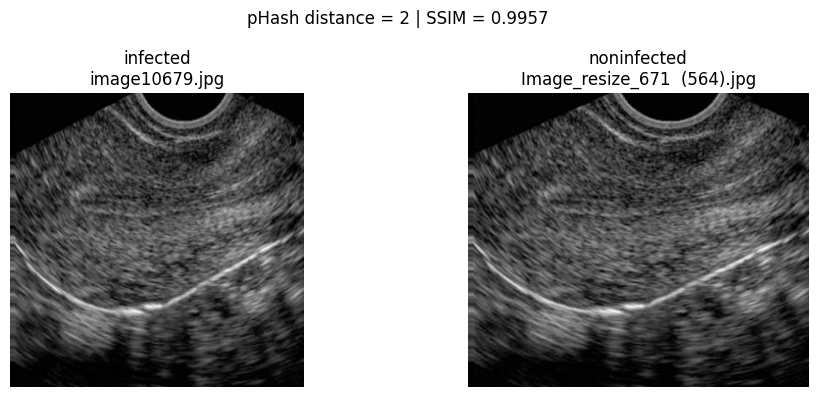

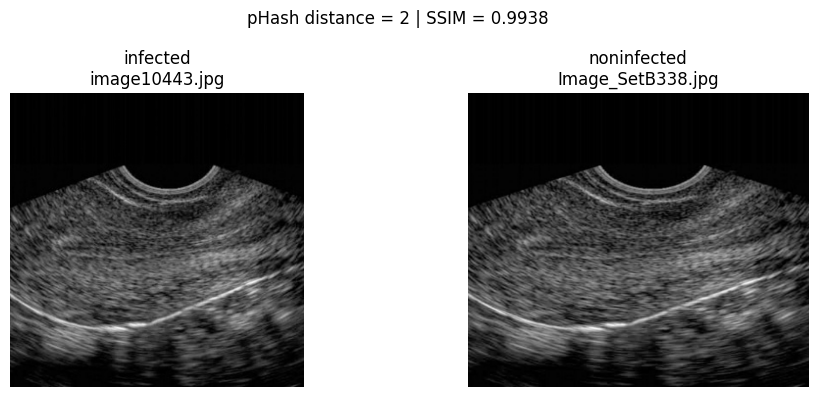

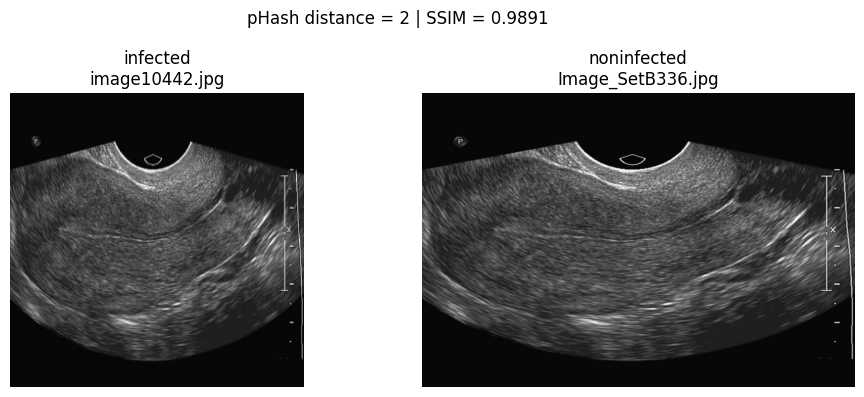

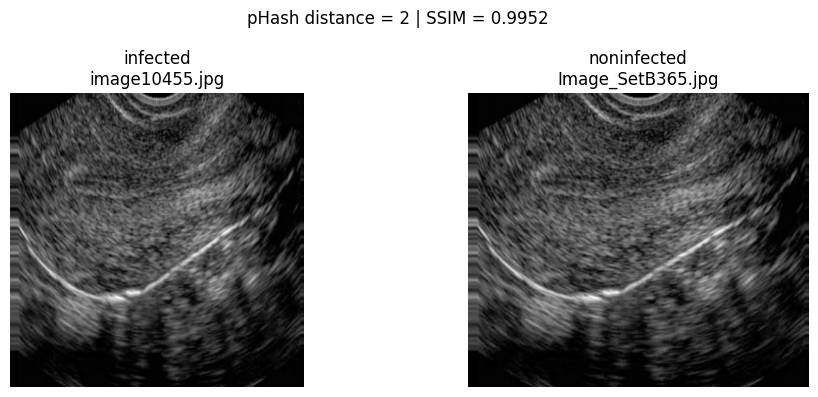

In [66]:
for result in phash2_strong:

    with Image.open(result["image1"]) as img1:
        img1 = img1.convert("RGB").copy()

    with Image.open(result["image2"]) as img2:
        img2 = img2.convert("RGB").copy()

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img1)
    plt.title(
        f"{result['class1']}\n"
        f"{os.path.basename(result['image1'])}"
    )
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(img2)
    plt.title(
        f"{result['class2']}\n"
        f"{os.path.basename(result['image2'])}"
    )
    plt.axis("off")

    plt.suptitle(
        f"pHash distance = {result['distance']} | "
        f"SSIM = {result['ssim']:.4f}"
    )

    plt.tight_layout()
    plt.show()

##Near-Duplicate Audit Findings

Perceptual hashing (pHash) was used to identify visually similar image
candidates. Structural Similarity Index (SSIM) was subsequently used
to verify the similarity of candidate pairs.

Among the cross-class candidates, 30 pairs had pHash distance 0 and
all had SSIM values >= 0.9878. Additionally, 4 pairs with pHash
distance 2 had SSIM values >= 0.95 and were visually confirmed as
near-identical images.

Therefore, 34 cross-class duplicate/label-conflict pairs involving
68 unique images were identified.

Because these images occur under conflicting class labels, both
members of each confirmed cross-class pair will be excluded from the
modeling dataset rather than assigning a label without supporting
evidence.

The resulting candidate modeling dataset contains 3,928 images:
3,150 infected and 778 noninfected images.

The original dataset will remain untouched, and the cleaned dataset
will be created separately.

##Create CLEAN_DATASET

In [72]:
# ============================================================
# STEP 11.2 — CREATE CLEAN DATASET
# ============================================================

import os
import hashlib
import shutil
from PIL import Image

# Original dataset
original_dataset = "/content/drive/MyDrive/PCOS_Project/PCOS_DATASET/PCOS"

# New clean dataset
clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

# Create folders
os.makedirs(os.path.join(clean_dataset, "infected"), exist_ok=True)
os.makedirs(os.path.join(clean_dataset, "noninfected"), exist_ok=True)


# ------------------------------------------------------------
# 1. Calculate exact file hash
# ------------------------------------------------------------

def get_file_hash(filepath):

    hasher = hashlib.sha256()

    with open(filepath, "rb") as f:
        while True:
            chunk = f.read(8192)

            if not chunk:
                break

            hasher.update(chunk)

    return hasher.hexdigest()


# ------------------------------------------------------------
# 2. Collect all readable images
# ------------------------------------------------------------

all_images = []

for class_name in ["infected", "noninfected"]:

    folder = os.path.join(original_dataset, class_name)

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        try:
            with Image.open(filepath) as img:
                img.verify()

            all_images.append({
                "path": filepath,
                "class": class_name,
                "filename": filename
            })

        except Exception:
            pass


print("Readable images found:", len(all_images))

Readable images found: 11784


In [73]:
# ============================================================
# FIND EXACT DUPLICATES
# ============================================================

hash_groups = {}

for item in all_images:

    file_hash = get_file_hash(item["path"])

    if file_hash not in hash_groups:
        hash_groups[file_hash] = []

    hash_groups[file_hash].append(item)


print("Unique image contents:", len(hash_groups))

Unique image contents: 3996


In [74]:
# ============================================================
# SELECT ONE REPRESENTATIVE IMAGE PER EXACT CONTENT
# ============================================================

unique_images = []

for file_hash, group in hash_groups.items():

    # Select the first file as representative
    representative = group[0]

    unique_images.append({
        "hash": file_hash,
        "path": representative["path"],
        "class": representative["class"],
        "filename": representative["filename"]
    })


print("Representative unique images:", len(unique_images))

Representative unique images: 3996


In [75]:
# ============================================================
# IDENTIFY EXACT-CONTENT GROUPS THAT MUST BE EXCLUDED
# ============================================================

excluded_hashes = set()

for file_hash, group in hash_groups.items():

    group_paths = {item["path"] for item in group}

    if group_paths.intersection(excluded_images):

        excluded_hashes.add(file_hash)


print("Exact-content groups excluded:", len(excluded_hashes))

Exact-content groups excluded: 68


In [76]:
# ============================================================
# CREATE FINAL CLEAN DATASET
# ============================================================

# Remove CLEAN_DATASET if it already exists
if os.path.exists(clean_dataset):
    shutil.rmtree(clean_dataset)

# Create fresh class folders
os.makedirs(os.path.join(clean_dataset, "infected"), exist_ok=True)
os.makedirs(os.path.join(clean_dataset, "noninfected"), exist_ok=True)


# ------------------------------------------------------------
# Copy ONE representative from each valid unique-content group
# ------------------------------------------------------------

clean_records = []

for file_hash, group in hash_groups.items():

    # Skip exact-content groups associated with
    # confirmed cross-class conflicts
    if file_hash in excluded_hashes:
        continue

    # Take ONE representative
    representative = group[0]

    source_path = representative["path"]
    class_name = representative["class"]
    filename = representative["filename"]

    destination_path = os.path.join(
        clean_dataset,
        class_name,
        filename
    )

    shutil.copy2(source_path, destination_path)

    clean_records.append({
        "filename": filename,
        "class": class_name,
        "source_path": source_path,
        "clean_path": destination_path,
        "sha256": file_hash
    })


print("Clean dataset created successfully!")
print("-" * 60)

infected_count = sum(
    1 for x in clean_records if x["class"] == "infected"
)

noninfected_count = sum(
    1 for x in clean_records if x["class"] == "noninfected"
)

print("Infected:", infected_count)
print("Noninfected:", noninfected_count)
print("Total:", len(clean_records))

Clean dataset created successfully!
------------------------------------------------------------
Infected: 3150
Noninfected: 778
Total: 3928


In [77]:
# ============================================================
# SAVE CLEANING AUDIT
# ============================================================

clean_audit_df = pd.DataFrame(clean_records)

audit_csv_path = os.path.join(
    clean_dataset,
    "clean_dataset_audit.csv"
)

clean_audit_df.to_csv(
    audit_csv_path,
    index=False
)

print("Cleaning audit saved to:")
print(audit_csv_path)

Cleaning audit saved to:
/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/clean_dataset_audit.csv


In [78]:
# ============================================================
# VERIFY FINAL CLEAN DATASET
# ============================================================

for class_name in ["infected", "noninfected"]:

    folder = os.path.join(clean_dataset, class_name)

    files = [
        f for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    ]

    print(f"{class_name}: {len(files)}")

print("-" * 40)

total_clean = 0

for class_name in ["infected", "noninfected"]:

    folder = os.path.join(clean_dataset, class_name)

    total_clean += len([
        f for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    ])

print("Total clean images:", total_clean)

infected: 3150
noninfected: 778
----------------------------------------
Total clean images: 3928


####Class Distribution

In [79]:
# ============================================================
# FINAL CLASS DISTRIBUTION
# ============================================================

import os

clean_classes = ["infected", "noninfected"]

print("FINAL CLEAN DATASET")
print("=" * 50)

total = 0

for class_name in clean_classes:

    folder = os.path.join(clean_dataset, class_name)

    count = len([
        f for f in os.listdir(folder)
        if os.path.isfile(os.path.join(folder, f))
    ])

    percentage = (count / 3928) * 100

    print(
        f"{class_name.capitalize():15s}: "
        f"{count:4d} images "
        f"({percentage:.2f}%)"
    )

    total += count

print("-" * 50)
print("Total images:", total)

FINAL CLEAN DATASET
Infected       : 3150 images (80.19%)
Noninfected    :  778 images (19.81%)
--------------------------------------------------
Total images: 3928


In [80]:
# ============================================================
# READABILITY CHECK
# ============================================================

from PIL import Image

for class_name in clean_classes:

    folder = os.path.join(clean_dataset, class_name)

    readable = 0
    unreadable = []

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        try:
            with Image.open(filepath) as img:
                img.verify()

            readable += 1

        except Exception:
            unreadable.append(filename)

    print(f"\n{class_name.capitalize()}")
    print("-" * 40)
    print("Readable:", readable)
    print("Unreadable:", len(unreadable))

    if unreadable:
        print("Unreadable files:")
        for filename in unreadable:
            print(" ", filename)


Infected
----------------------------------------
Readable: 3150
Unreadable: 0

Noninfected
----------------------------------------
Readable: 778
Unreadable: 0


In [81]:
# ============================================================
#FINAL DIMENSION AND IMAGE MODE AUDIT
# ============================================================

from PIL import Image
from collections import Counter

for class_name in clean_classes:

    folder = os.path.join(clean_dataset, class_name)

    dimensions = Counter()
    modes = Counter()

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        try:
            with Image.open(filepath) as img:

                dimensions[img.size] += 1
                modes[img.mode] += 1

        except Exception:
            pass

    print(f"\n{class_name.capitalize()}")
    print("-" * 50)

    print("Number of unique dimensions:",
          len(dimensions))

    print("\nImage modes:")
    print(modes)

    print("\nTop 15 dimensions:")

    for dimension, count in dimensions.most_common(15):

        print(f"{dimension}: {count}")


Infected
--------------------------------------------------
Number of unique dimensions: 1362

Image modes:
Counter({'RGB': 3150})

Top 15 dimensions:
(300, 300): 728
(225, 225): 113
(343, 343): 105
(320, 320): 89
(299, 266): 78
(280, 259): 74
(233, 216): 71
(266, 299): 28
(150, 150): 26
(259, 280): 23
(216, 233): 20
(149, 133): 14
(140, 129): 14
(116, 108): 13
(171, 171): 12

Noninfected
--------------------------------------------------
Number of unique dimensions: 8

Image modes:
Counter({'RGB': 778})

Top 15 dimensions:
(984, 848): 205
(850, 578): 144
(630, 436): 125
(315, 160): 104
(848, 984): 76
(578, 850): 52
(436, 630): 38
(160, 315): 34


In [82]:
# ============================================================
# FINAL EXACT DUPLICATE CHECK
# ============================================================

clean_hashes = {}
duplicate_groups = []

for class_name in clean_classes:

    folder = os.path.join(clean_dataset, class_name)

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        file_hash = get_file_hash(filepath)

        if file_hash not in clean_hashes:

            clean_hashes[file_hash] = {
                "class": class_name,
                "filename": filename,
                "path": filepath
            }

        else:

            duplicate_groups.append({
                "hash": file_hash,
                "first": clean_hashes[file_hash],
                "duplicate": {
                    "class": class_name,
                    "filename": filename,
                    "path": filepath
                }
            })


print("Clean dataset images:", len(clean_hashes))
print("Exact duplicate pairs found:",
      len(duplicate_groups))

Clean dataset images: 3928
Exact duplicate pairs found: 0


##Generate pHash for the 3,928 clean images

In [83]:
# ============================================================
# pHASH FOR CLEAN DATASET
# ============================================================

import imagehash
from PIL import Image
import os

clean_phash_data = []

for class_name in ["infected", "noninfected"]:

    folder = os.path.join(clean_dataset, class_name)

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if not os.path.isfile(filepath):
            continue

        try:
            with Image.open(filepath) as img:

                img = img.convert("RGB")

                phash = imagehash.phash(img)

            clean_phash_data.append({
                "path": filepath,
                "filename": filename,
                "class": class_name,
                "phash": phash
            })

        except Exception as e:
            print("Error:", filepath, e)


print("Clean images analyzed:", len(clean_phash_data))

Clean images analyzed: 3928


In [84]:
# ============================================================
# SAME-CLASS pHASH CANDIDATES
# ============================================================

same_class_candidates = []

for i in range(len(clean_phash_data)):

    img1 = clean_phash_data[i]

    for j in range(i + 1, len(clean_phash_data)):

        img2 = clean_phash_data[j]

        # Only compare images from the SAME class
        if img1["class"] != img2["class"]:
            continue

        distance = img1["phash"] - img2["phash"]

        if distance <= 4:

            same_class_candidates.append({
                "image1": img1,
                "image2": img2,
                "distance": distance
            })


print(
    "Same-class pHash candidate pairs:",
    len(same_class_candidates)
)

Same-class pHash candidate pairs: 8267


In [3]:
from collections import Counter

same_class_distance_distribution = Counter(
    pair["distance"]
    for pair in same_class_candidates
)

print("Same-class pHash distance distribution")
print("-" * 60)

for distance, count in sorted(
    same_class_distance_distribution.items()
):

    print(
        f"pHash distance {distance}: {count} pairs"
    )

NameError: name 'same_class_candidates' is not defined

In [86]:
# ============================================================
# SSIM VERIFICATION OF SAME-CLASS pHash-0
# ============================================================

same_class_phash0 = [
    pair
    for pair in same_class_candidates
    if pair["distance"] == 0
]

print(
    "Same-class pHash-0 pairs:",
    len(same_class_phash0)
)

Same-class pHash-0 pairs: 1089


In [87]:
# Calculate SSIM for pHash-0 same-class pairs

same_class_phash0_ssim = []

for idx, pair in enumerate(same_class_phash0):

    path1 = pair["image1"]["path"]
    path2 = pair["image2"]["path"]

    score = calculate_ssim(path1, path2)

    same_class_phash0_ssim.append({
        "image1": path1,
        "image2": path2,
        "class": pair["image1"]["class"],
        "distance": 0,
        "ssim": score
    })

    if (idx + 1) % 100 == 0:
        print(f"Processed: {idx + 1}/{len(same_class_phash0)}")


print("\nSSIM calculations completed:",
      len(same_class_phash0_ssim))

Processed: 100/1089
Processed: 200/1089
Processed: 300/1089
Processed: 400/1089
Processed: 500/1089
Processed: 600/1089
Processed: 700/1089
Processed: 800/1089
Processed: 900/1089
Processed: 1000/1089

SSIM calculations completed: 1089


In [88]:
# ============================================================
# SSIM STATISTICS — SAME-CLASS pHash-0
# ============================================================

scores = [
    result["ssim"]
    for result in same_class_phash0_ssim
]

print("Same-class pHash-0 SSIM statistics")
print("-" * 60)

print("Number of comparisons:", len(scores))
print("Minimum SSIM:", min(scores))
print("Maximum SSIM:", max(scores))
print("Average SSIM:", sum(scores) / len(scores))

Same-class pHash-0 SSIM statistics
------------------------------------------------------------
Number of comparisons: 1089
Minimum SSIM: 0.14197075596067724
Maximum SSIM: 0.9955155945001536
Average SSIM: 0.5996104820118454


In [89]:
# ============================================================
# SSIM THRESHOLD ANALYSIS
# ============================================================

thresholds = [0.90, 0.95, 0.97, 0.98, 0.99]

print("Same-class pHash-0 SSIM threshold analysis")
print("-" * 60)

for threshold in thresholds:

    count = sum(
        score >= threshold
        for score in scores
    )

    percentage = (count / len(scores)) * 100

    print(
        f"SSIM >= {threshold}: "
        f"{count} pairs ({percentage:.2f}%)"
    )

Same-class pHash-0 SSIM threshold analysis
------------------------------------------------------------
SSIM >= 0.9: 145 pairs (13.31%)
SSIM >= 0.95: 85 pairs (7.81%)
SSIM >= 0.97: 29 pairs (2.66%)
SSIM >= 0.98: 6 pairs (0.55%)
SSIM >= 0.99: 5 pairs (0.46%)


In [90]:
# ============================================================
# STRONG SAME-CLASS DUPLICATE PAIRS
# ============================================================

strong_same_class_pairs = [
    result
    for result in same_class_phash0_ssim
    if result["ssim"] >= 0.95
]

print(
    "Strong same-class duplicate pairs:",
    len(strong_same_class_pairs)
)

Strong same-class duplicate pairs: 85


In [2]:
# ============================================================
# BUILD CONNECTED DUPLICATE GROUPS
# ============================================================

class UnionFind:

    def __init__(self):
        self.parent = {}

    def find(self, x):

        if x not in self.parent:
            self.parent[x] = x

        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])

        return self.parent[x]

    def union(self, a, b):

        root_a = self.find(a)
        root_b = self.find(b)

        if root_a != root_b:
            self.parent[root_b] = root_a


uf = UnionFind()

for pair in strong_same_class_pairs:

    img1 = pair["image1"]
    img2 = pair["image2"]

    uf.union(
        img1,
        img2
    )


# Build groups
duplicate_groups_same_class = {}

for image in uf.parent:

    root = uf.find(image)

    if root not in duplicate_groups_same_class:
        duplicate_groups_same_class[root] = []

    duplicate_groups_same_class[root].append(image)


print(
    "Same-class duplicate groups:",
    len(duplicate_groups_same_class)
)

NameError: name 'strong_same_class_pairs' is not defined

In [1]:
# ============================================================
# DUPLICATE GROUP SIZE DISTRIBUTION
# ============================================================

from collections import Counter

group_sizes = Counter(
    len(group)
    for group in duplicate_groups_same_class.values()
)

print("Same-class duplicate group size distribution")
print("-" * 60)

for size, count in sorted(group_sizes.items()):

    print(
        f"{count} groups contain {size} images"
    )


print(
    "\nTotal images involved in strong "
    "same-class groups:",
    sum(len(group)
        for group in duplicate_groups_same_class.values())
)

NameError: name 'duplicate_groups_same_class' is not defined